In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)#configuration settings
pd.set_option("display.max_rows", 100)#print 100 rows before truncating

print("Libraries imported successfully!")
df = pd.read_excel("../data/Telco_customer_churn.xlsx")#read excel

print("Dataset loaded successfully!")
df.head()





Libraries imported successfully!
Dataset loaded successfully!


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [3]:
import pandas as pd
df=pd.read_excel("cleaned_telco_customers.xlsx")
df=df.drop(columns=["Churn Score"])

categorical_col = df.select_dtypes(include=["object", "string"]).columns.tolist()

categorical_col.remove("Churn Label")
numerical_col = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
numerical_col.remove("Churn Value")
print(categorical_col)
print(numerical_col)

['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']
['Tenure Months', 'Monthly Charges', 'Total Charges', 'CLTV', 'Total charges']


statistic =0.9038
pvalue =0.0000
not distributed normally
statistic =0.9209
pvalue =0.0000
not distributed normally
statistic =0.8604
pvalue =0.0000
not distributed normally
statistic =0.9619
pvalue =0.0000
not distributed normally
statistic =0.8604
pvalue =0.0000
not distributed normally


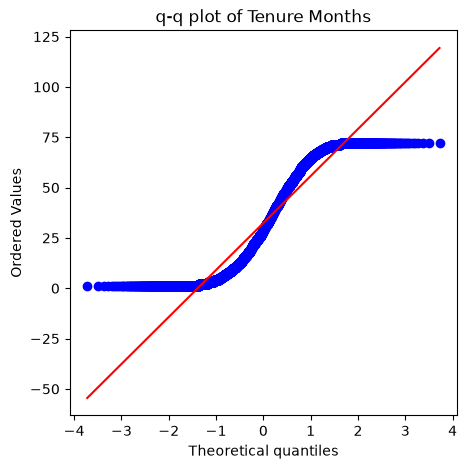

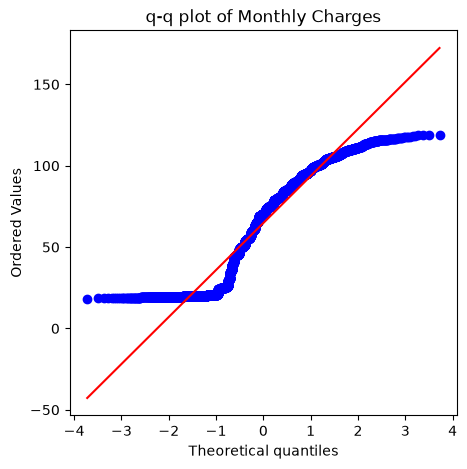

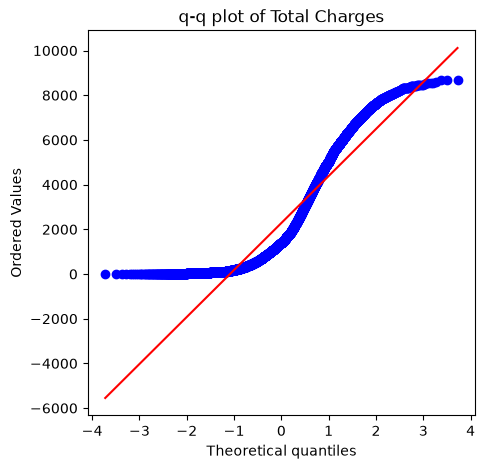

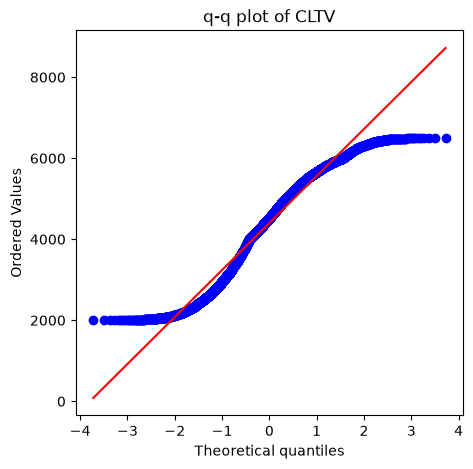

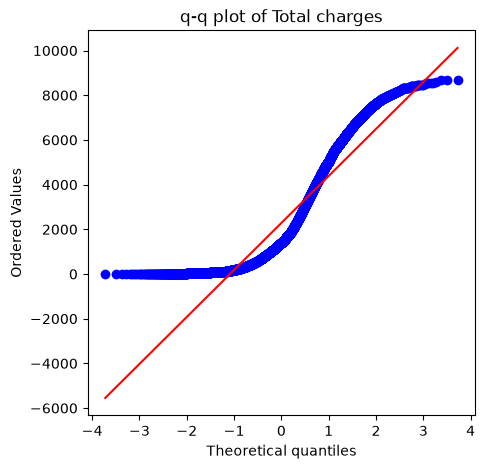

In [5]:
#mann-whitney u test
#check if data distubuted normally or not
'''import matplotlib.pyplot as plt
numerical_columns = [
    "Tenure Months",
    "Monthly Charges",
    "Total Charges",
    "CLTV"
]

for col in numerical_columns:
    plt.figure(figsize=(6,4))
    plt.hist(df[col], bins=30, edgecolor="black")
    plt.title(f"Histogram of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()'''

from scipy.stats import shapiro

for col in numerical_col:
    stat,p=shapiro(df[col])

    print(f"statistic ={stat:.4f}")
    print(f"pvalue ={p:.4f}")

    if p>0.05:
        print("normally distributed")
    else:
        print("not distributed normally")

import matplotlib.pyplot as plt
from scipy.stats import probplot
for col in numerical_col:
    plt.figure(figsize=(5,5))
    probplot(df[col],dist="norm",plot=plt)
    plt.title(f"q-q plot of {col}")
    plt.show()
        